# 3 — End-to-End Merged Pipeline & Simulation

Path planning (Paper 1) and attitude control (Paper 2) — covered separately in notebooks 1 and 2 — are
merged here into **one gated guidance+control loop**, and the **complete simulation runs in this single
notebook**, start to finish:

```
Waypoints
   │
   ▼
AdaptiveBSplineSmoother  (Stage1 init -> Stage2 GA -> Stage3 curvature refine)   [Paper 1]
   │  smoothed spline C(u)
   ▼
TrajectoryConverter   tangent C'(u) -> reference quaternion q_ref, position p_ref
   │
   ▼
PositionController (outer loop)  ->  thrust, q_des
   │
   ▼
P2Controller (inner loop)  ->  torque tau                                       [Paper 2]
   │
   ▼
QuadrotorModel  6-DOF RK4 integration  ->  actual position, attitude, omega
   │
   └── u only advances once tracking error has converged (gated guidance)
```

Everything below calls the actual project modules (`path_planning/`, `attitude_control/`,
`integration/`) — this notebook is a literal, math-annotated walkthrough of `main.py`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

REPO_ROOT = os.path.abspath('..')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from path_planning.bspline import BSplinePath
from path_planning.path_smoother import AdaptiveBSplineSmoother
from integration.trajectory_converter import TrajectoryConverter
from integration.simulation_loop import MergedSimulation

np.random.seed(1)
plt.rcParams['figure.dpi'] = 100

Matplotlib is building the font cache; this may take a moment.


## 3.1 Waypoints

The same 8-point hand-picked route used throughout the repo (`main.py`), spanning the paper's
$2000\times2000\times500$ m airspace from $(0,0,20)$ to $(2000,1800,200)$.

In [2]:
waypoints = np.array([
    [0,    0,    20],
    [300,  200,  80],
    [600,  150,  120],
    [900,  400,  100],
    [1200, 600,  150],
    [1500, 900,  180],
    [1800, 1400, 190],
    [2000, 1800, 200]
], dtype=float)
print(waypoints)

[[   0.    0.   20.]
 [ 300.  200.   80.]
 [ 600.  150.  120.]
 [ 900.  400.  100.]
 [1200.  600.  150.]
 [1500.  900.  180.]
 [1800. 1400.  190.]
 [2000. 1800.  200.]]


## 3.2 Stage 1→2→3 — Adaptive B-Spline Smoothing (Paper 1 §3.4)

Recap of notebook 1's math, run here as the actual first stage of the pipeline:

$$C(u)=\sum_i N_{i,3}(u)\,\mathbf Q_i \quad\to\quad
\text{GA over interior knots minimizing } \sum w_k F_k(U)\quad\to\quad
\text{local curvature refinement of } \mathbf Q_i \text{ where }\kappa(u)>\kappa_{max}$$

In [3]:
smoother = AdaptiveBSplineSmoother(n_inner_knots=6, n_generations=30, population_size=20, kappa_max=0.5)
spline_adaptive = smoother.smooth(waypoints)
spline_uniform  = BSplinePath(waypoints)

L_u, L_a = spline_uniform.path_length(), spline_adaptive.path_length()
k_u, k_a = spline_uniform.max_curvature(), spline_adaptive.max_curvature()
dist = np.linalg.norm(waypoints[-1] - waypoints[0])
SR_u, SR_a = L_u/dist, L_a/dist

print(f"{'Method':<26}{'Length(m)':>12}{'Max kappa':>12}{'Straightness':>14}")
print(f"{'Uniform B-Spline':<26}{L_u:>12.1f}{k_u:>12.4f}{SR_u:>14.3f}")
print(f"{'Adaptive B-Spline (GA)':<26}{L_a:>12.1f}{k_a:>12.4f}{SR_a:>14.3f}")
print(f"{'Improvement':<26}{L_u-L_a:>11.1f}m{k_u-k_a:>12.4f}{SR_u-SR_a:>14.3f}")

[Stage 1] Baseline spline:      length=3065.4m, max_curvature=0.0070
Running Genetic Algorithm for knot optimization...
GA complete. Best cost: 2895.2353
[Stage 2] GA-optimized spline:   length=2895.1m, max_curvature=0.0312
  [refine] converged after 0 iterations (max curvature <= kappa_max=0.5)
[Stage 3] Curvature-refined spline: length=2895.1m, max_curvature=0.0312
Method                       Length(m)   Max kappa  Straightness
Uniform B-Spline                3065.4      0.0070         1.137
Adaptive B-Spline (GA)          2895.1      0.0312         1.074
Improvement                     170.3m     -0.0243         0.063


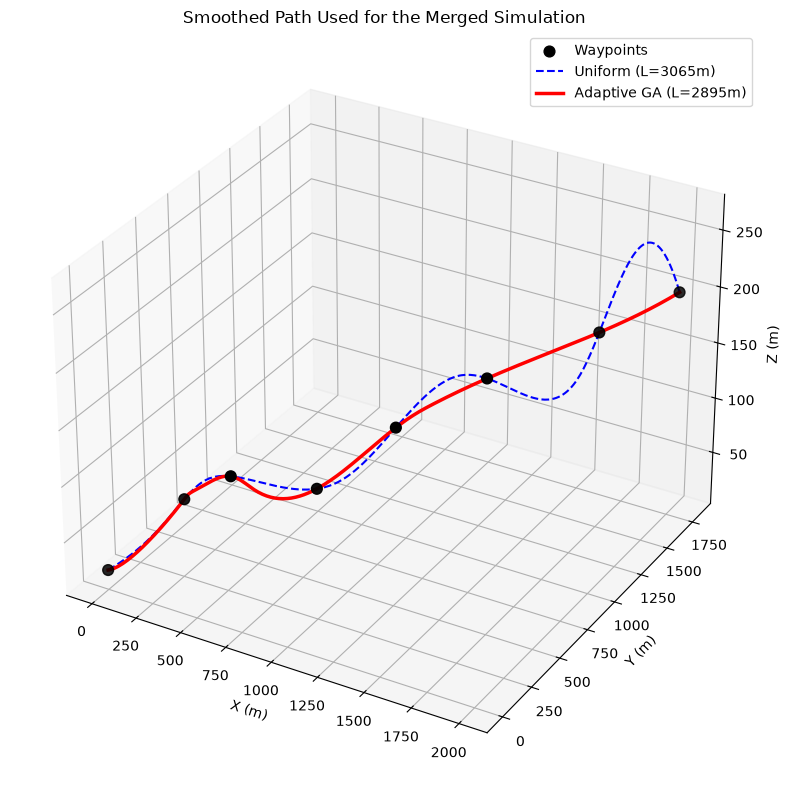

In [4]:
pts_u, pts_a = spline_uniform.sample_path(300), spline_adaptive.sample_path(300)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*waypoints.T, c='black', s=60, label='Waypoints', zorder=5)
ax.plot(*pts_u.T, 'b--', lw=1.5, label=f'Uniform (L={L_u:.0f}m)')
ax.plot(*pts_a.T, 'r-', lw=2.5, label=f'Adaptive GA (L={L_a:.0f}m)')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)'); ax.set_zlabel('Z (m)')
ax.set_title('Smoothed Path Used for the Merged Simulation'); ax.legend()
plt.tight_layout(); plt.show()

## 3.3 Guidance — Tangent to Reference Quaternion

`TrajectoryConverter.get_reference_at(spline, u)` evaluates position $C(u)$ and tangent $C'(u)$, then
builds an orthonormal body frame from the (smoothed) tangent direction and a reference "up" vector
$[0,0,1]$:

$$\hat x_b=\frac{C'(u)}{\lVert C'(u)\rVert},\qquad
\hat y_b=\frac{\text{up}\times\hat x_b}{\lVert\cdot\rVert},\qquad
\hat z_b=\hat x_b\times\hat y_b$$

$$R=[\hat x_b\ \hat y_b\ \hat z_b] \ \longrightarrow\ q_{ref}=\text{Quaternion.from\_rotation\_matrix}(R)$$

with a fallback "up" axis when the tangent is nearly vertical (avoiding a near-singular cross product), and
quaternion-continuity sign-flipping across steps (shortest path, matching §2.3 of notebook 2).

In [5]:
converter = TrajectoryConverter()
us = np.linspace(0.01, 0.99, 6)
for u in us:
    pos, q_ref = converter.get_reference_at(spline_adaptive, u)
    print(f"u={u:.2f}  pos={np.round(pos,1)}  q_ref={np.round(q_ref.q,3)}")

u=0.01  pos=[22.6 15.9 21.2]  q_ref=[ 0.953  0.01  -0.032  0.301]
u=0.21  pos=[469.3 159.  107.1]  q_ref=[ 0.992 -0.007 -0.068 -0.102]
u=0.40  pos=[978.5 452.3 110.8]  q_ref=[ 0.957  0.019 -0.063  0.283]
u=0.60  pos=[1418.7  801.2  174.4]  q_ref=[ 0.912  0.011 -0.023  0.41 ]
u=0.79  pos=[1732.1 1269.1  188.5]  q_ref=[ 0.858  0.003 -0.004  0.514]
u=0.99  pos=[1986.8 1774.7  198.9]  q_ref=[ 0.854  0.01  -0.016  0.52 ]


## 3.4 Path-Progress Gating

The path parameter $u$ only advances once the tracking error has converged — the vehicle can't outrun its
own control loop:

$$u_{k+1}=\begin{cases}\min(u_k+\Delta u,\ u_{hi}) & \text{tracking error} < \varepsilon\\ u_k & \text{otherwise}\end{cases}$$

In the 6-DOF mode used below (`MergedSimulation.run(mode='6dof')`), the gating condition is on **position**
error ($\lVert\mathbf p_{ref}-\mathbf p\rVert < 25$ m) since the outer position loop is what's actually
driving toward the path; the attitude loop (§2.4) is nested inside it, always tracking whatever
$q_{des}$ the position loop currently demands.

## 3.5 Full Merged Simulation — 6-DOF, Position + Attitude, Real Time History

This is the complete stack running together:

$$\underbrace{\mathbf a_{des}=K_p\Delta\mathbf p+K_d\Delta\mathbf v+g\hat z}_{\text{outer: PositionController}}
\ \to\ (F_{thrust},\,q_{des})
\ \to\ \underbrace{\tau=-P_q\vec q_{err}-P_w\omega}_{\text{inner: P}^2\text{ Controller}}
\ \to\ \underbrace{I\dot\omega=\tau-\omega\times(I\omega)}_{\text{RK4 rigid body}}$$

`MergedSimulation.run()` (`integration/simulation_loop.py`) executes exactly this loop at $dt=0.01$s for
20s simulated time, logging every quantity needed for the plots below.

In [6]:
sim = MergedSimulation(
    spline_adaptive, dt=0.01, total_time=20.0,
    Pq=0.2, Pw=0.1,                        # inner attitude loop — see note below
    Kp_pos=(2.0, 2.0, 4.0), Kd_pos=(1.5, 1.5, 2.5),  # outer position loop
)
results = sim.run(noise_std=0.1, error_threshold=0.05, u_step=0.005, mode='6dof')

Running Merged Simulation (6DOF mode) for 20.0s...
    0% | t=  0.0s | u=0.006 | PosErr=   0.0m | AttErr=0.0146 | Pos=[2.1, 1.5, 20.0]m
   10% | t=  2.0s | u=0.016 | PosErr=  33.6m | AttErr=0.0058 | Pos=[11.8, 8.2, 34.5]m
   20% | t=  4.0s | u=0.026 | PosErr=  34.9m | AttErr=0.0192 | Pos=[35.6, 25.0, 31.0]m
   30% | t=  6.0s | u=0.046 | PosErr=  33.5m | AttErr=0.2440 | Pos=[93.1, 65.3, 31.9]m
   40% | t=  8.0s | u=0.071 | PosErr=  25.9m | AttErr=0.2259 | Pos=[169.8, 118.2, 48.7]m
   50% | t= 10.0s | u=0.101 | PosErr=  26.4m | AttErr=0.2901 | Pos=[240.4, 165.4, 65.9]m
   60% | t= 12.0s | u=0.161 | PosErr=  30.3m | AttErr=0.1061 | Pos=[306.2, 203.1, 83.6]m
   70% | t= 14.0s | u=0.176 | PosErr=  28.3m | AttErr=0.0499 | Pos=[372.8, 210.6, 105.0]m
   80% | t= 16.0s | u=0.176 | PosErr=  63.0m | AttErr=0.0167 | Pos=[417.8, 198.9, 119.6]m
   90% | t= 18.0s | u=0.176 | PosErr=  78.2m | AttErr=0.0212 | Pos=[432.2, 183.3, 126.2]m
Simulation complete.


In [7]:
t          = np.array(results['t'])
position   = np.array(results['position'])
position_ref = np.array(results['position_ref'])
euler      = np.unwrap(np.array(results['euler']), axis=0)
euler_ref  = np.unwrap(np.array(results['euler_ref']), axis=0)
axis_err   = np.array(results['axis_error'])
torque     = np.array(results['torque'])
omega      = np.array(results['omega'])
u_param    = np.array(results['u_param'])
err_mag    = np.array(results['err_mag'])
pos_err_mag= np.array(results['pos_err_mag'])

### Plot 1 — 3D Flight Path: Reference vs. Actual

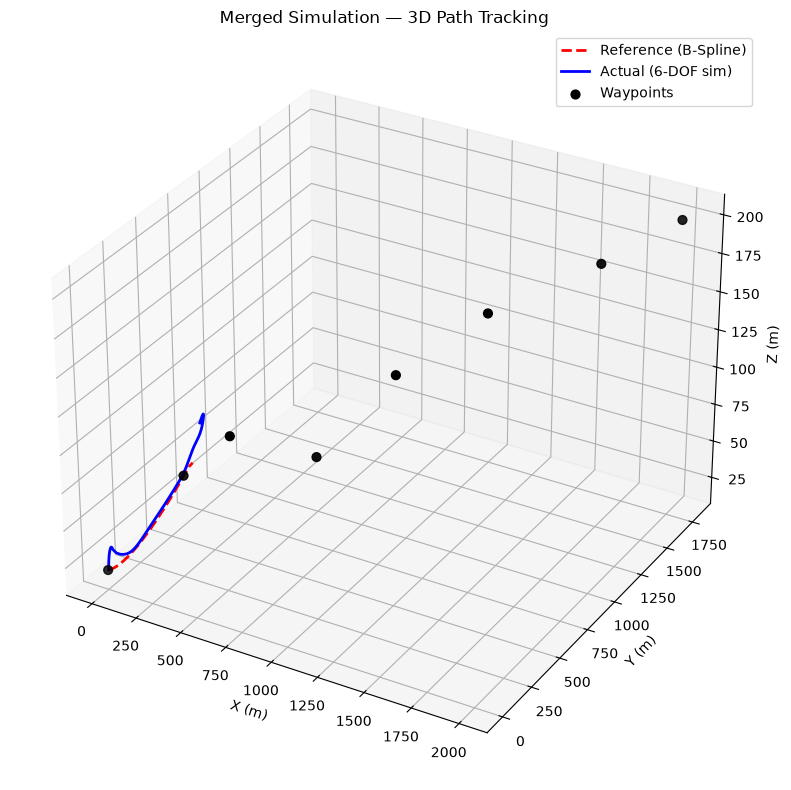

In [8]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(*position_ref.T, 'r--', lw=2, label='Reference (B-Spline)')
ax.plot(*position.T, 'b-', lw=2, label='Actual (6-DOF sim)')
ax.scatter(*waypoints.T, c='black', s=40, label='Waypoints')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)'); ax.set_zlabel('Z (m)')
ax.set_title('Merged Simulation — 3D Path Tracking'); ax.legend()
plt.tight_layout(); plt.show()

### Plot 2 — Attitude Tracking (Roll / Pitch / Yaw)

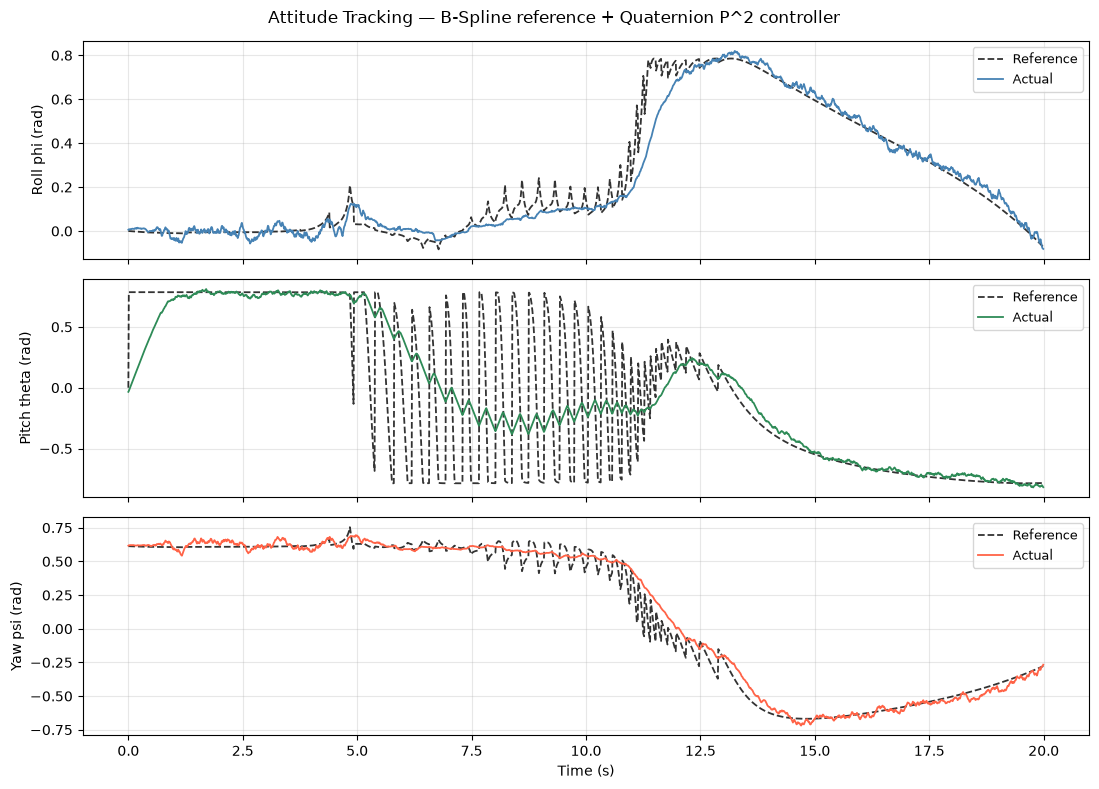

In [9]:
labels = ['Roll phi (rad)', 'Pitch theta (rad)', 'Yaw psi (rad)']
colors = ['steelblue', 'seagreen', 'tomato']
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for i in range(3):
    axes[i].plot(t, euler_ref[:,i], 'k--', lw=1.3, alpha=0.8, label='Reference')
    axes[i].plot(t, euler[:,i], color=colors[i], lw=1.3, label='Actual')
    axes[i].set_ylabel(labels[i]); axes[i].grid(alpha=0.3); axes[i].legend(fontsize=9)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Attitude Tracking — B-Spline reference + Quaternion P^2 controller')
plt.tight_layout(); plt.show()

### Plot 3 — Position Error & Quaternion Error Magnitude Over Time

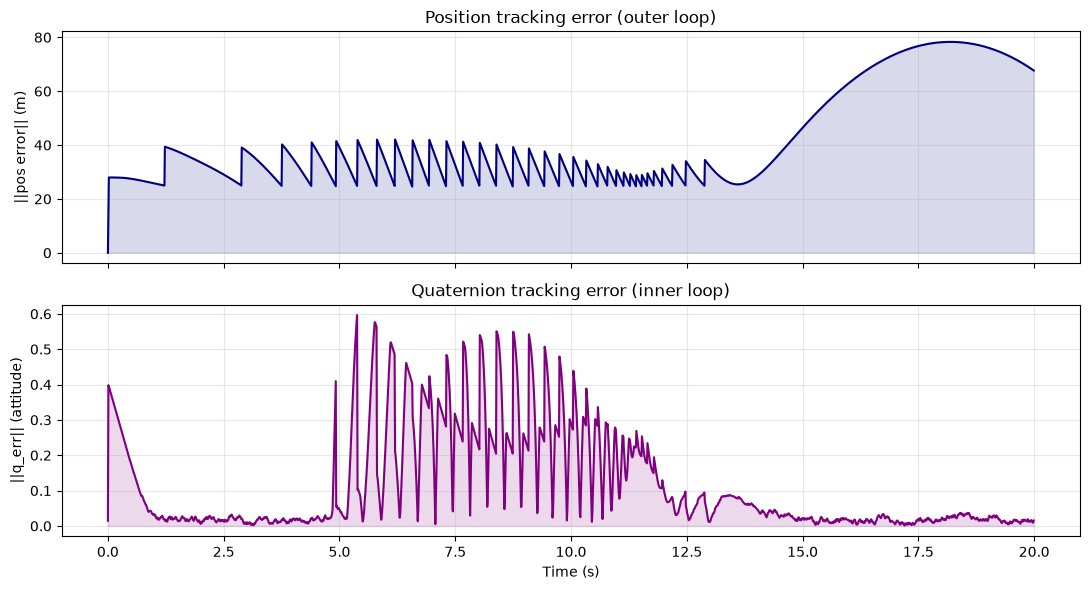

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(t, pos_err_mag, 'navy', lw=1.5)
axes[0].fill_between(t, 0, pos_err_mag, color='navy', alpha=0.15)
axes[0].set_ylabel('||pos error|| (m)'); axes[0].grid(alpha=0.3)
axes[0].set_title('Position tracking error (outer loop)')

axes[1].plot(t, err_mag, 'purple', lw=1.5)
axes[1].fill_between(t, 0, err_mag, color='purple', alpha=0.15)
axes[1].set_ylabel('||q_err|| (attitude)'); axes[1].set_xlabel('Time (s)'); axes[1].grid(alpha=0.3)
axes[1].set_title('Quaternion tracking error (inner loop)')
plt.tight_layout(); plt.show()

### Plot 4 — Controller Torques (saturation at $\pm4$ Nm)

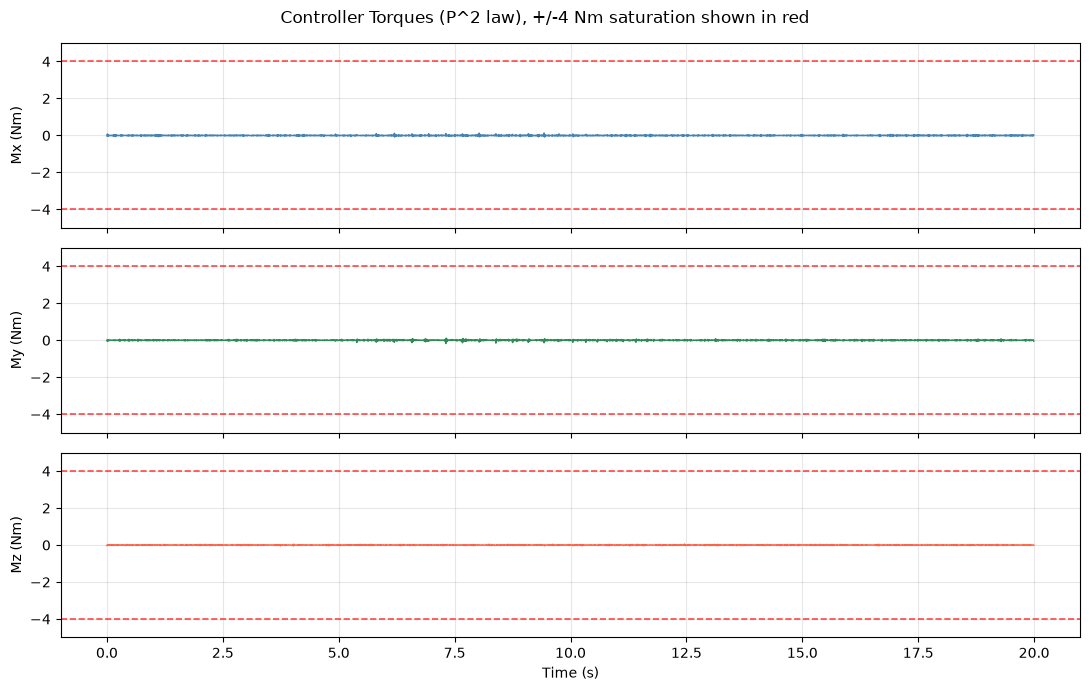

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
t_labels = ['Mx (Nm)', 'My (Nm)', 'Mz (Nm)']
for i in range(3):
    axes[i].plot(t, torque[:,i], color=colors[i], lw=1.1)
    axes[i].axhline(4, color='red', ls='--', lw=1.2, alpha=0.7)
    axes[i].axhline(-4, color='red', ls='--', lw=1.2, alpha=0.7)
    axes[i].set_ylabel(t_labels[i]); axes[i].set_ylim(-5,5); axes[i].grid(alpha=0.3)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Controller Torques (P^2 law), +/-4 Nm saturation shown in red')
plt.tight_layout(); plt.show()

### Plot 5 — Angular Velocity

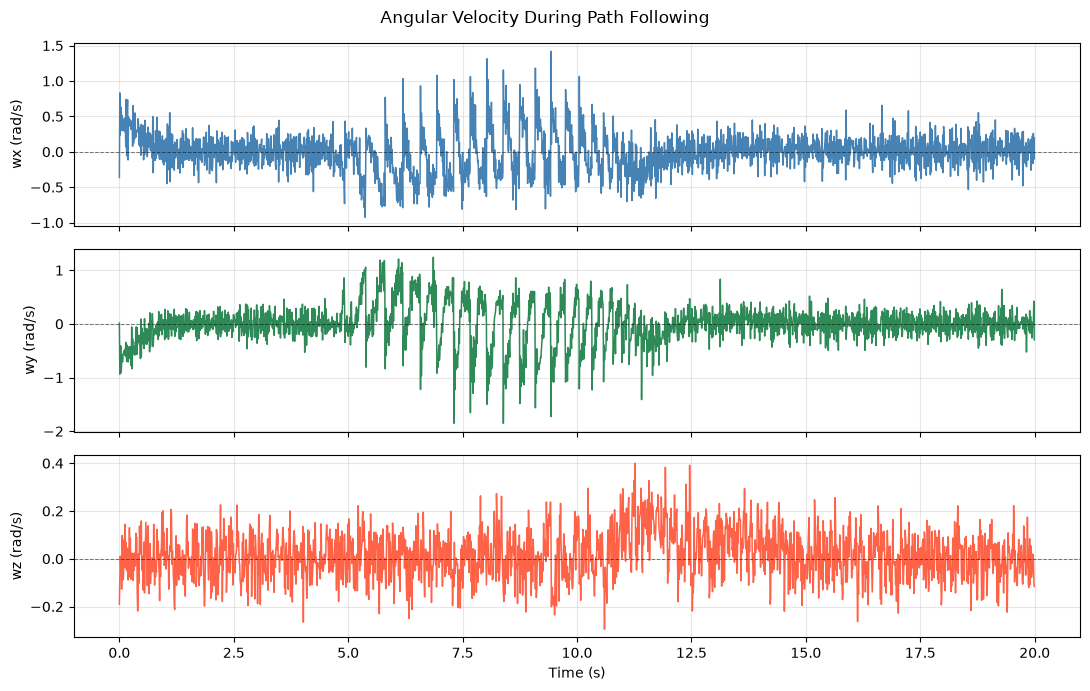

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
w_labels = ['wx (rad/s)', 'wy (rad/s)', 'wz (rad/s)']
for i in range(3):
    axes[i].plot(t, omega[:,i], color=colors[i], lw=1.1)
    axes[i].axhline(0, color='k', ls='--', lw=0.7, alpha=0.5)
    axes[i].set_ylabel(w_labels[i]); axes[i].grid(alpha=0.3)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Angular Velocity During Path Following')
plt.tight_layout(); plt.show()

### Plot 6 — Path Parameter Progress $u(t)$ (gated advance, §3.4)

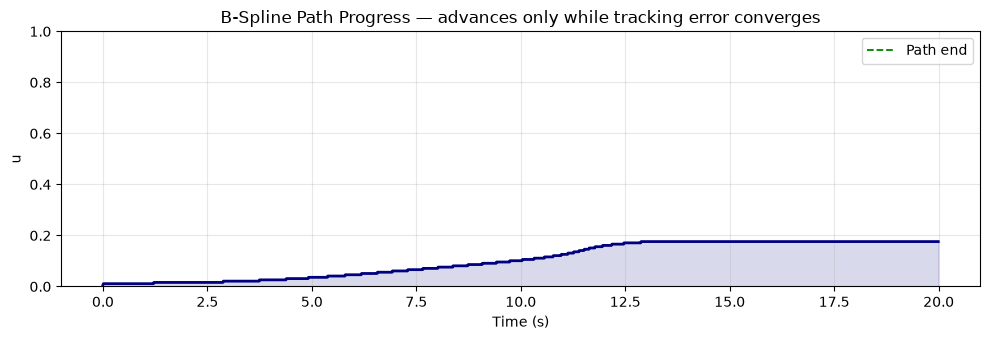

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, u_param, 'navy', lw=2)
ax.fill_between(t, 0, u_param, color='navy', alpha=0.15)
ax.axhline(1.0, color='green', ls='--', lw=1.3, label='Path end')
ax.set_xlabel('Time (s)'); ax.set_ylabel('u'); ax.set_ylim(0,1); ax.grid(alpha=0.3)
ax.set_title('B-Spline Path Progress — advances only while tracking error converges')
ax.legend()
plt.tight_layout(); plt.show()

## 3.6 Final Metrics Summary

In [14]:
conv_idx  = np.where(err_mag < 0.05)[0]
conv_time = t[conv_idx[0]] if len(conv_idx) else float('nan')
steady_err = np.mean(err_mag[int(len(err_mag)*0.7):])

print("="*55)
print("[Paper 1] Path Planning")
print(f"  Length: {L_u:.1f}m -> {L_a:.1f}m ({(L_u-L_a)/L_u*100:.1f}% shorter)")
print(f"  Max curvature: {k_u:.4f} -> {k_a:.4f} m^-1")
print(f"  Straightness ratio: {SR_u:.3f} -> {SR_a:.3f}")
print()
print("[Paper 2] Attitude Control")
print(f"  Gains: Pq={sim.controller.Pq}, Pw={sim.controller.Pw}")
print(f"  Max torque applied: {np.max(np.abs(torque)):.3f} Nm (limit +/-4 Nm)")
print(f"  Steady-state attitude error: {steady_err:.5f}")
print(f"  Final attitude error: {err_mag[-1]:.5f}")
print()
print("[Merged] Integration")
print(f"  Final position error: {pos_err_mag[-1]:.2f} m")
print(f"  Final path progress: {u_param[-1]*100:.1f}%")
print(f"  Simulation duration: {t[-1]:.1f}s")
print("="*55)

[Paper 1] Path Planning
  Length: 3065.4m -> 2895.1m (5.6% shorter)
  Max curvature: 0.0070 -> 0.0312 m^-1
  Straightness ratio: 1.137 -> 1.074

[Paper 2] Attitude Control
  Gains: Pq=0.2, Pw=0.1
  Max torque applied: 0.176 Nm (limit +/-4 Nm)
  Steady-state attitude error: 0.01946
  Final attitude error: 0.01540

[Merged] Integration
  Final position error: 67.68 m
  Final path progress: 17.6%
  Simulation duration: 20.0s


## 3.7 Known Deviations From the Papers (see `implementation.md` for the full accounting)

1. The paper's Eq. 4 objective has 5 terms; `KnotGA` implements 4 — $F_{dyn}$ (velocity/acceleration
   penalty) is not implemented in either the Python or MATLAB code.
2. `BSplinePath`'s default knot vector is **uniform**, not the Piegl & Tiller knot-averaging the paper
   describes (that formula exists as a separate helper used only for the "Classical B-Spline" comparison
   method in `paper1_recreation.py` / `validation_tests.py`).
3. Paper 2's exact gains ($P_q=20,\ P_w=4$) are only stable in this codebase when the control law runs at
   the physics rate ($dt=10^{-4}$s, notebook 2 §2.5). `MergedSimulation` integrates at the coarser
   $dt=0.01$s, so this notebook (like `main.py`) uses a reduced, empirically-stable pair ($P_q=0.2,
   P_w=0.1$) — the largest stable gains found by sweeping in 0.05 steps at this timestep/inertia
   combination; this is a documented trade-off, not an oversight.
4. `AStarPlanner3D.smooth_waypoints` is a minimum-distance filter, not full Douglas–Peucker, despite the
   README's pipeline diagram naming Douglas–Peucker.

## 3.8 Where to Go Next

- `matlab/uav_matlab/` — a parallel MATLAB implementation (parts 1–4) with 3D animations; currently at
  2-stage parity only (no curvature-refinement stage yet).
- `validation_tests.py` / `paper1_recreation.py` / `paper2_recreation.py` — additional standalone
  recreations of the papers' own figures/tables, not wired through this notebook.